---
title: Analysis of Explicit Songs
author: George Dokken
date: today
---

## **Can we see shifts in the amount of explicit songs? Or in the reason for being rated explicit?**

We will look at the total amount of explicit songs and how the reason for explicit ratings change over time. The main dataset used will be *Billboard Hot 100 Number Ones* (documentation [here](https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-08-26/readme.md)), specifically the columns `explicit`, `lyrics`, and `lyrical_topic`.

We begin by importing our libraries. We used `pandas` for reading in and manipulating dataframes, as well as `pyplot` and `seaborn` to graph our data. 

In [30]:
# import statements
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Data Overview

We read in and begin EDA for our dataset. There are 105 columns, so we use the documentation instead of listing them all below. 

In [31]:
df = pd.read_csv('data/billboard.csv') # read in dataframe
df.columns # look at columns

Index(['song', 'artist', 'date', 'weeks_at_number_one', 'non_consecutive',
       'rating_1', 'rating_2', 'rating_3', 'overall_rating', 'divisiveness',
       ...
       'featured_in_a_then_contemporary_play', 'written_for_a_film',
       'featured_in_a_then_contemporary_film', 'written_for_a_t_v_show',
       'featured_in_a_then_contemporary_t_v_show', 'associated_with_dance',
       'topped_the_charts_by_multiple_artist', 'double_a_side',
       'eurovision_entry', 'u_s_artwork'],
      dtype='str', length=105)

We subset our dataframe to only include the columns of interest for this analysis, including the song titles, artists, date, explicit status, and lyrical information. The new dataframe is called `ex`.

In [32]:
ex = df[['song', 'artist', 'date', 'weeks_at_number_one', 'explicit', 'lyrics', 'lyrical_topic']] # subsetting dataframe
ex.head() # exploring the first five rows

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic
0,Poor Little Fool,Ricky Nelson,1958-08-04T00:00:00Z,2,0,I used to play around with hearts.That hastene...,Lost Love
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18T00:00:00Z,5,0,NaN,Flying;Dreaming
2,Little Star,The Elegants,1958-08-25T00:00:00Z,1,0,Where are you little star.Where are you.Twinkl...,Longing for Love
3,It's All in the Game,Tommy Edwards,1958-09-29T00:00:00Z,6,0,Many a tear have to fall.But it's all in the g...,Love
4,It's Only Make Believe,Conway Twitty,1958-11-10T00:00:00Z,2,0,People see us everywhere.They think you really...,Lost Love


Getting the counts from the `explicit` column reveals that there 940 non-explicit songs and 237 explicit song that have reached the #1 spot.

In [33]:
ex['explicit'].value_counts() # explicit column counts

explicit
0    940
1    237
Name: count, dtype: int64

Creating two new columns for the year and decade of when the song first reached #1 and verify that they look correct.

In [34]:
ex['year'] = ex['date'].str[:4] # create year column
ex['decade'] = (ex['year'].astype(int) // 10) * 10 # create decade column
ex.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade
0,Poor Little Fool,Ricky Nelson,1958-08-04T00:00:00Z,2,0,I used to play around with hearts.That hastene...,Lost Love,1958,1950
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18T00:00:00Z,5,0,NaN,Flying;Dreaming,1958,1950
2,Little Star,The Elegants,1958-08-25T00:00:00Z,1,0,Where are you little star.Where are you.Twinkl...,Longing for Love,1958,1950
3,It's All in the Game,Tommy Edwards,1958-09-29T00:00:00Z,6,0,Many a tear have to fall.But it's all in the g...,Love,1958,1950
4,It's Only Make Believe,Conway Twitty,1958-11-10T00:00:00Z,2,0,People see us everywhere.They think you really...,Lost Love,1958,1950


### Timeline

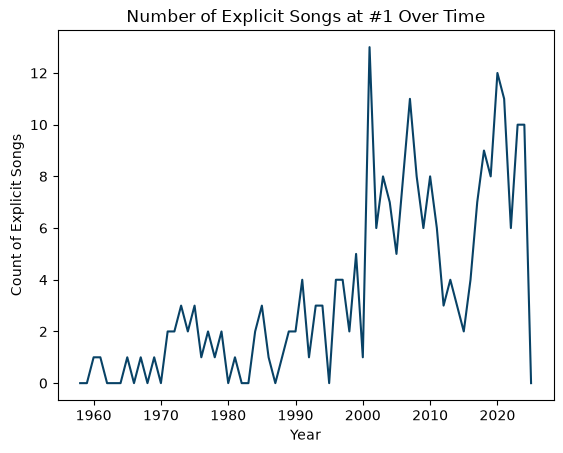

In [35]:
yearly = sns.lineplot(data=ex, x='year', y='explicit', errorbar=None, estimator=sum, color="#084266") # Creating a lineplot
yearly.set_xticks([2,12,22,32,42,52,62]) # setting the xticks so the years don't overlapp excessively 
yearly.set_xlabel("Year")
yearly.set_ylabel("Count of Explicit Songs")
yearly.set_title("Number of Explicit Songs at #1 Over Time") # creating a title and changing the x and y labels
plt.show()

The line plot above displays the total counts of explicit songs in the top #1 billboard spot over time. There is a clear increase, with sharp peaks starting around the years 2000 and 2020. The overall increase is likely a byproduct of society becoming more comfortable with non-PG topics over time. The specific peaks are likely related to the social movements and changes of those times. (blah blah blah 2000s defiance, blah blah blah 2020s loss of hope/reality check)

In [ ]:
# FIX THIS
yearly = sns.lineplot(data=ex, x='year', y='explicit', errorbar=None, estimator=sum, color="#084266") # Creating a lineplot
yearly.set_xticks([2,12,22,32,42,52,62]) # setting the xticks so the years don't overlapp excessively 
yearly.set_xlabel("Year")
yearly.set_ylabel("Count of Explicit Songs")
yearly.set_title("Number of Explicit Songs at #1 Over Time") # creating a title and changing the x and y labels
plt.show()

The line plot above displays the proportion of explicit in #1. This is important to look at because what if songs are lasting longer? What if there are more of them? IDK bro

### Explicit Categories

There is not a column in the dataframe that tells us why a song was marked as explicit. 

The reasonings behind explicit songs are incredibly important insights into what concerns were at the forefront of society, what topics were being normalized, and what societal boundaries were being pushed. 

While the data does not have these reasonings, it does have columns for the `lyrics` and `lyrical_topic` which we can use to determine the likely reason a song received it's explicit rating. While there is not a fully standardized way the music industry has decided on ratings, most labels mark songs explicit if it falls into 1 or more of the 4 categoriges: sexual content, drug/alcohol content, violence, and profanity.

Only songs rated explicit need to be catagorized, so we filter out any songs without the explicit rating and save the new dataframe as `exonly`.

In [36]:
exonly = ex[ex['explicit'] == True] # filtering dataset
exonly.head()

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade
36,Mr. Custer,Larry Verne,1960-10-10T00:00:00Z,1,1,That famous day in history.The men of the 7th ...,War,1960,1960
60,Big Bad John,Jimmy Dean,1961-11-06T00:00:00Z,5,1,Every morning at the mine you could see him ar...,Work;Death,1961,1960
139,(I Can't Get No) Satisfaction,The Rolling Stones,1965-07-10T00:00:00Z,4,1,I can't get no satisfaction.I can't get no sat...,Lust/Sex;Anger;Restlessness,1965,1960
187,Light My Fire,The Doors,1967-07-29T00:00:00Z,3,1,You know that it would be untrue.You know that...,Lust/Sex,1967,1960
217,Honky Tonk Women,The Rolling Stones,1969-08-23T00:00:00Z,4,1,I met a gin soaked barroom queen in Memphis.Sh...,Lust/Sex,1969,1960


First we need to look at the number of unique entries and value counts in the `lyrical_topic` column. This shows that some of the songs have more than one topic separated by semicolons, this is important to keep in mind when writing the code to filter based of topic.

In [37]:
print(exonly["lyrical_topic"].nunique()) # the number of unique topics
exonly["lyrical_topic"].value_counts() # the largest topics

118


lyrical_topic
Lust/Sex                              56
Lost Love                             17
Lost Love;Bad Relationships           10
Bragging                               6
Lust/Sex;Dancing                       5
                                      ..
Bragging;Fame                          1
Infidelity;Lust/Sex;Empowerment        1
Anger;Bragging                         1
Lust/Sex;Partying;Bragging;Respect     1
Anger;Bragging;Fighting                1
Name: count, Length: 118, dtype: int64

There are two main methods of flagging songs, one that uses lyrical topics and one that use the song lyrics. Below are lists of words (strings) that will flag different categorizations. 

There are lists of lyrical topics (gotten from the data documentation) that likely relate to sexual content, drugs/alcohol, and violence. There are lists of words that likely relate to sexual content or are categorized (by different music labels) as slurs/profanity to check against the lyrics.

In [38]:
sexual_topic = ['Lust/Sex', 'Love', 'Lost Love', 'Masturbation', 'Infidelity', 'Bad Relationships', 'Longing for Love', 'Marriage', 'Getting Back Together']
sexual_words = ['penis', 'vagina', 'tits', 'blowjob', 'boner', 'clit', 'cum', 'pussy']
drug_alcohol_topic = ['Addiction', 'Partying']
violence_topic = ['War', 'Death', 'Fighting', 'Violence', 'Murder', 'Revenge', 'Anger', 'Bad Behavior']
profanity_slur_words = ['ass', 'balls', 'bastard', 'bitch', 'blowjob', 'boner', 'clit', 'cock', 'cum', 'cunt', 'damn', 'dick', 'dyke', 'faggot', 'fuck', 'hell', 'nigger', 'pecker', 'piss', 'pussy', 'shit', 'tits', 'twat', 'whore', 'fucker', 'motherfucker', 'fag', 'fucking', 'damnit']

Below is a dataframe with only 5 rows to test the process of categorization.

In [39]:
extest = ex.head() # smaller subset of our dataframe
extest

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade
0,Poor Little Fool,Ricky Nelson,1958-08-04T00:00:00Z,2,0,I used to play around with hearts.That hastene...,Lost Love,1958,1950
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18T00:00:00Z,5,0,NaN,Flying;Dreaming,1958,1950
2,Little Star,The Elegants,1958-08-25T00:00:00Z,1,0,Where are you little star.Where are you.Twinkl...,Longing for Love,1958,1950
3,It's All in the Game,Tommy Edwards,1958-09-29T00:00:00Z,6,0,Many a tear have to fall.But it's all in the g...,Love,1958,1950
4,It's Only Make Believe,Conway Twitty,1958-11-10T00:00:00Z,2,0,People see us everywhere.They think you really...,Lost Love,1958,1950


Defined is a function `check_topic` that takes in a list of topics, row index, and dataframe then returns a boolean for if any of the topics in the list appear in the row.

In [40]:
# crete function to check for topic in row
def check_topic(list, row, df):
    """"
    Function will search a row in a dataframe for matching values between the 7th column of the dataframe and the provided list
    """
    for topic in list: # for each of the items in the list
        if topic in str(df.iloc[row,6]): # check to see if item is in data at row - row and column - 7
                return True
    return False

# using the test dataframe and sexual topics list to see if the above function is working correctly
sexual_test = []
for row in range(len(extest)):
    sexual_test.append(check_topic(sexual_topic, row, extest))

print(sexual_test) # all but the second song is catagorized as True which is what we wanted

[True, False, True, True, True]


Now that we know the method above works we will create similar functions to 'check_topic'. These funciton will check the lyrics or check both topics and lyrics for the catagorizations that are using both. 

In [41]:
def check_lyrics(list,row, df):
    """
    Function will search a row in a dataframe for matching values between the 6th column of the dataframe and the provided list
    """
    for word in list:
        if word in str(df.iloc[row,5]):
                return True
    return False

In [42]:
def check_topic_and_lyrics(topic_list,word_list,row):
    """
    Function will search a row in exonly for matching values between the 7th column of the dataframe and the topic list and 
    function will search a row in exonly for matching values between the 6th column of the dataframe and the word list
    """
    for topic in topic_list: 
        if topic in str(exonly.iloc[row,6]):
            return True
    for word in word_list:
        if word in str(exonly.iloc[row,5]):
            return True
    return False

#### Creating columns for explicit reasoning

The functions defined above were used in conjunction with our lists of keywords to create lists of booleans. This boolean list was then used to create new columns in our dataframe.

In [43]:
sexual = []
for row in range(len(exonly)): # for row in our explicit dataset
    sexual.append(check_topic_and_lyrics(sexual_topic,sexual_words,row)) # append list with boolean returned from function

drug_alcohol = []
for row in range(len(exonly)):
    drug_alcohol.append(check_topic(drug_alcohol_topic,row,exonly))

violence = []
for row in range(len(exonly)):
    violence.append(check_topic(violence_topic,row,exonly))

profanity_slur = []
for row in range(len(exonly)):
    profanity_slur.append(check_lyrics(profanity_slur_words,row,exonly))


In [44]:
# creating boolean columns for if a song was likely marked explicit for sexual content, drug_alcohol content, violent content, or explicit words
exonly['sexual'] = sexual
exonly['drug_alcohol'] = drug_alcohol
exonly['violence'] = violence
exonly['profanity_slur'] = profanity_slur

exonly.head() # looking at the first five songs in our data with the updated columns

,song,artist,date,weeks_at_number_one,explicit,lyrics,lyrical_topic,year,decade,sexual,drug_alcohol,violence,profanity_slur
36,Mr. Custer,Larry Verne,1960-10-10T00:00:00Z,1,1,That famous day in history.The men of the 7th ...,War,1960,1960,False,False,True,False
60,Big Bad John,Jimmy Dean,1961-11-06T00:00:00Z,5,1,Every morning at the mine you could see him ar...,Work;Death,1961,1960,False,False,True,True
139,(I Can't Get No) Satisfaction,The Rolling Stones,1965-07-10T00:00:00Z,4,1,I can't get no satisfaction.I can't get no sat...,Lust/Sex;Anger;Restlessness,1965,1960,True,False,True,False
187,Light My Fire,The Doors,1967-07-29T00:00:00Z,3,1,You know that it would be untrue.You know that...,Lust/Sex,1967,1960,True,False,False,False
217,Honky Tonk Women,The Rolling Stones,1969-08-23T00:00:00Z,4,1,I met a gin soaked barroom queen in Memphis.Sh...,Lust/Sex,1969,1960,True,False,False,False


Below are graphs for each of the 4 categories over time.

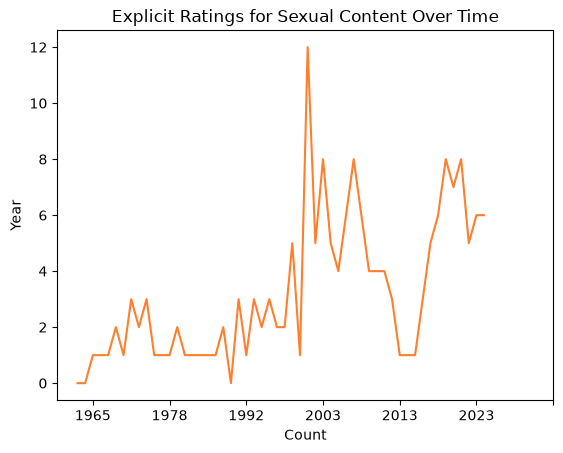

In [ ]:
yearly = sns.lineplot(data=exonly, x='year', y='sexual', estimator=sum, errorbar=None, color="#fe7f2d") # creating the line based on total explicit songs with sexual contant each year
yearly.set_xticks([2,12,22,32,42,52,62]) # setting xticks for no x axis overlap
plt.title("Explicit Ratings for Sexual Content Over Time") # creating a title
plt.xlabel("Year") # labeling x and y
plt.ylabel("Count")
plt.show()

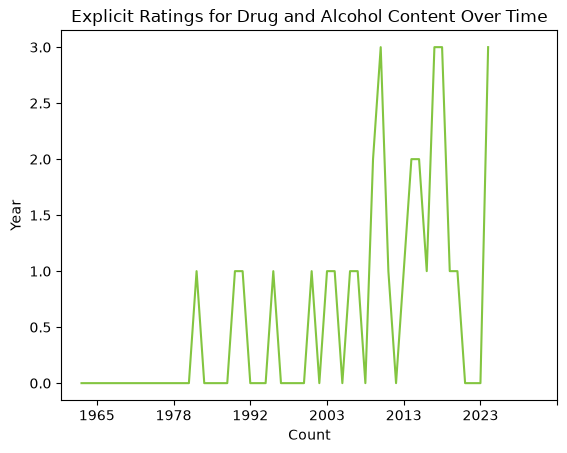

In [ ]:
yearly = sns.lineplot(data=exonly, x='year', y='drug_alcohol', estimator=sum, errorbar=None, color="#83c540")
yearly.set_xticks([2,12,22,32,42,52,62])
plt.title("Explicit Ratings for Drug and Alcohol Content Over Time")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

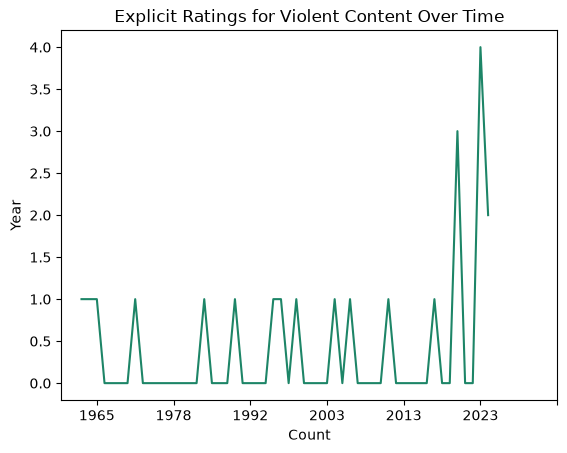

In [ ]:
yearly = sns.lineplot(data=exonly, x='year', y='violence', estimator=sum, errorbar=None, color="#1d8567")
yearly.set_xticks([2,12,22,32,42,52,62])
plt.title("Explicit Ratings for Violent Content Over Time")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

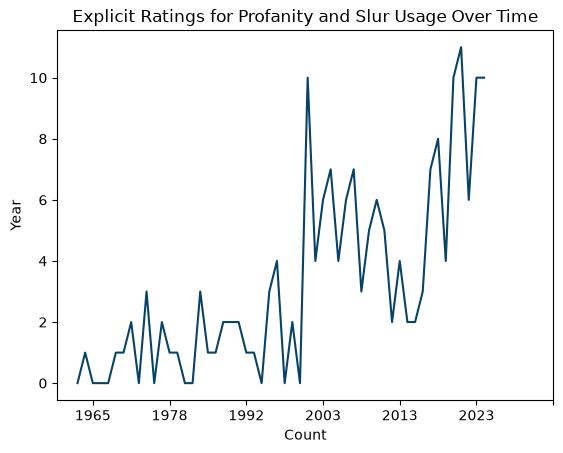

In [ ]:
yearly = sns.lineplot(data=exonly, x='year', y='profanity_slur', estimator=sum, errorbar=None, color="#084266")
yearly.set_xticks([2,12,22,32,42,52,62])
plt.title("Explicit Ratings for Profanity and Slur Usage Over Time")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

Text(0, 0.5, 'Count')

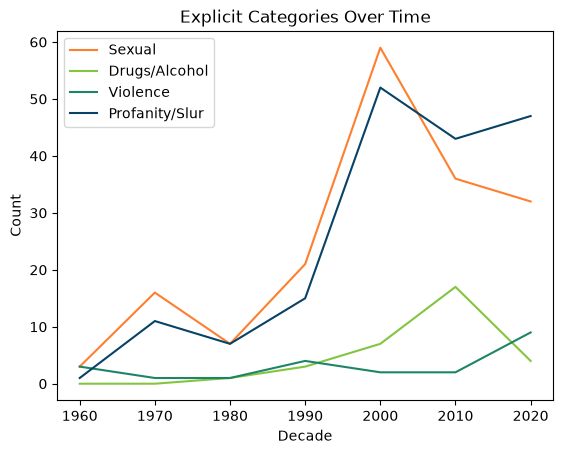

In [ ]:
sns.lineplot(data=exonly, x="decade", y="sexual", estimator=sum, errorbar=None, color="#fe7f2d", label="Sexual") # creating each line for the different explicit reasoning
sns.lineplot(data=exonly, x="decade", y="drug_alcohol", estimator=sum, errorbar=None, color="#83c540", label="Drugs/Alcohol")
sns.lineplot(data=exonly, x="decade", y="violence", estimator=sum, errorbar=None, color="#1d8567", label="Violence")
sns.lineplot(data=exonly, x="decade", y="profanity_slur", estimator=sum, errorbar=None, color="#084266", label="Profanity/Slur")
plt.title("Explicit Categories Over Time")
plt.xlabel("Decade")
plt.ylabel("Count")

The final graph shows all four of the different explicit reasonings over time. This makes the changed over time more comparable. The largest spike is around the 2000 which makes sense as state information before. There are also smaller spikes at 1970 and 2010. During those periods blank and blank were happening.

Outside of the overall growth and spikes there is a trend of sexual contant and profanity/slurs being the reason for explicit rating on a much larger scale than Violence and Drugs/Alcohol. Here are my thoughts on this...